# Module 04: Split-Plot Amnesia
**Analyzing a split-plot field trial as a flat CRD and celebrating fake irrigation significance** · *~5 min*

*Created by [Lungh](https://github.com/lunganlungpg) · part of [Experimental Design Gone Wrong](https://github.com/lunganlungpg/experimental-design-gone-wrong)*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lunganlungpg/experimental-design-gone-wrong/blob/main/04_split_plot_amnesia/04_split_plot_amnesia.ipynb)


## 1. The Setup (The Blunder)

An agronomist runs a split-plot wheat trial across 5 field blocks: each block has **2 large whole-plot irrigation strips** (`Rainfed` vs `Irrigated`, randomly assigned to the two strip positions; 10 whole-plot strips total), and each strip is split into **5 narrow cultivar subplots** (`Var_1`–`Var_5`, randomly assigned to subplot positions; 50 subplots total). The randomization is real at both levels, which is exactly why each level needs its own error term. At harvest, they export all 50 subplot rows into a single tidy CSV, promptly forget that irrigation pipes were only randomized 10 times across bumpy field strips, and feed the spreadsheet into a flat Completely Randomized Two-Way ANOVA (`yield ~ irrigation * cultivar`). Thrilled by `p = 0.0029` on irrigation, they miss that their model just judged irrigation using tiny subplot noise (`df = 40`) instead of the massive whole-plot strip error (`df = 4`).

In [1]:
# Works locally out of the box; in Google Colab, clones the repo for src/.
import subprocess
import sys
from pathlib import Path

GITHUB_REPO = "lunganlungpg/experimental-design-gone-wrong"

for root in (Path.cwd(), Path.cwd().parent):
    if (root / "src" / "simulate_blunders.py").exists():
        if str(root) not in sys.path:
            sys.path.insert(0, str(root))
        break
else:
    clone_dir = Path("/content/experimental-design-gone-wrong")
    if not clone_dir.exists():
        subprocess.run(
            ["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(clone_dir)],
            check=True,
        )
    sys.path.insert(0, str(clone_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

from src.simulate_blunders import (
    PALETTE,
    build_comparison_table,
    format_p_value,
    set_publication_style,
    simulate_split_plot,
    split_plot_anova,
)

set_publication_style()
df = simulate_split_plot(seed=21)  # see the docstring: chosen to show the blunder
print(f"Subplots: {len(df)} | Whole-plot strips: {df['whole_plot_id'].nunique()} | Blocks: {df['block'].nunique()}")
df.head(8)

Subplots: 50 | Whole-plot strips: 10 | Blocks: 5


,subplot_id,block,irrigation,whole_plot_id,strip_pos,cultivar,subplot_pos,yield_t_ha
0,1,Block_1,Rainfed,B1_Rainfed,1,Var_2,1,3.226
1,2,Block_1,Rainfed,B1_Rainfed,1,Var_1,2,3.105
2,3,Block_1,Rainfed,B1_Rainfed,1,Var_4,3,3.404
3,4,Block_1,Rainfed,B1_Rainfed,1,Var_5,4,3.713
4,5,Block_1,Rainfed,B1_Rainfed,1,Var_3,5,3.705
5,6,Block_1,Irrigated,B1_Irrigated,2,Var_5,1,6.109
6,7,Block_1,Irrigated,B1_Irrigated,2,Var_2,2,6.016
7,8,Block_1,Irrigated,B1_Irrigated,2,Var_3,3,5.922


## 2. The Crime (Naive Analysis)

By treating all 50 subplots as completely randomized, the naive two-way ANOVA pools strip-to-strip heterogeneity with subplot noise and inflates denominator degrees of freedom from **4** to **40**.

In [2]:
naive_crd = smf.ols("yield_t_ha ~ C(irrigation) * C(cultivar, Sum)", data=df).fit()
aov_crd = anova_lm(naive_crd, typ=2)

p_irr_bad = float(aov_crd.loc["C(irrigation)", "PR(>F)"])
f_irr_bad = float(aov_crd.loc["C(irrigation)", "F"])
est_bad = float(naive_crd.params["C(irrigation)[T.Irrigated]"])
ci_bad = naive_crd.conf_int().loc["C(irrigation)[T.Irrigated]"].tolist()

print(aov_crd.round(4))
print(f"\nNaive CRD Irrigation effect: {est_bad:+.2f} t/ha, F(1, {int(naive_crd.df_resid)}) = {f_irr_bad:.2f}, p = {format_p_value(p_irr_bad)}")

                                 sum_sq    df        F  PR(>F)
C(irrigation)                    4.6922   1.0  10.1006  0.0029
C(cultivar, Sum)                 1.0565   4.0   0.5686  0.6869
C(irrigation):C(cultivar, Sum)   0.2244   4.0   0.1207  0.9743
Residual                        18.5819  40.0      NaN     NaN

Naive CRD Irrigation effect: +0.61 t/ha, F(1, 40) = 10.10, p = 0.0029


## 3. The Reality Check (Visual Punchline)

Left: each of the 10 whole-plot strips bounces wildly from block to block (`Rainfed` vs `Irrigated` lines even cross!), while the 5 cultivar subplots march in tight lockstep inside every strip. Right: comparing the true **Whole-Plot Error(a)** Mean Square against the naive CRD pooled residual and **Subplot Error(b)** shows exactly how the F-ratio got artificially inflated.

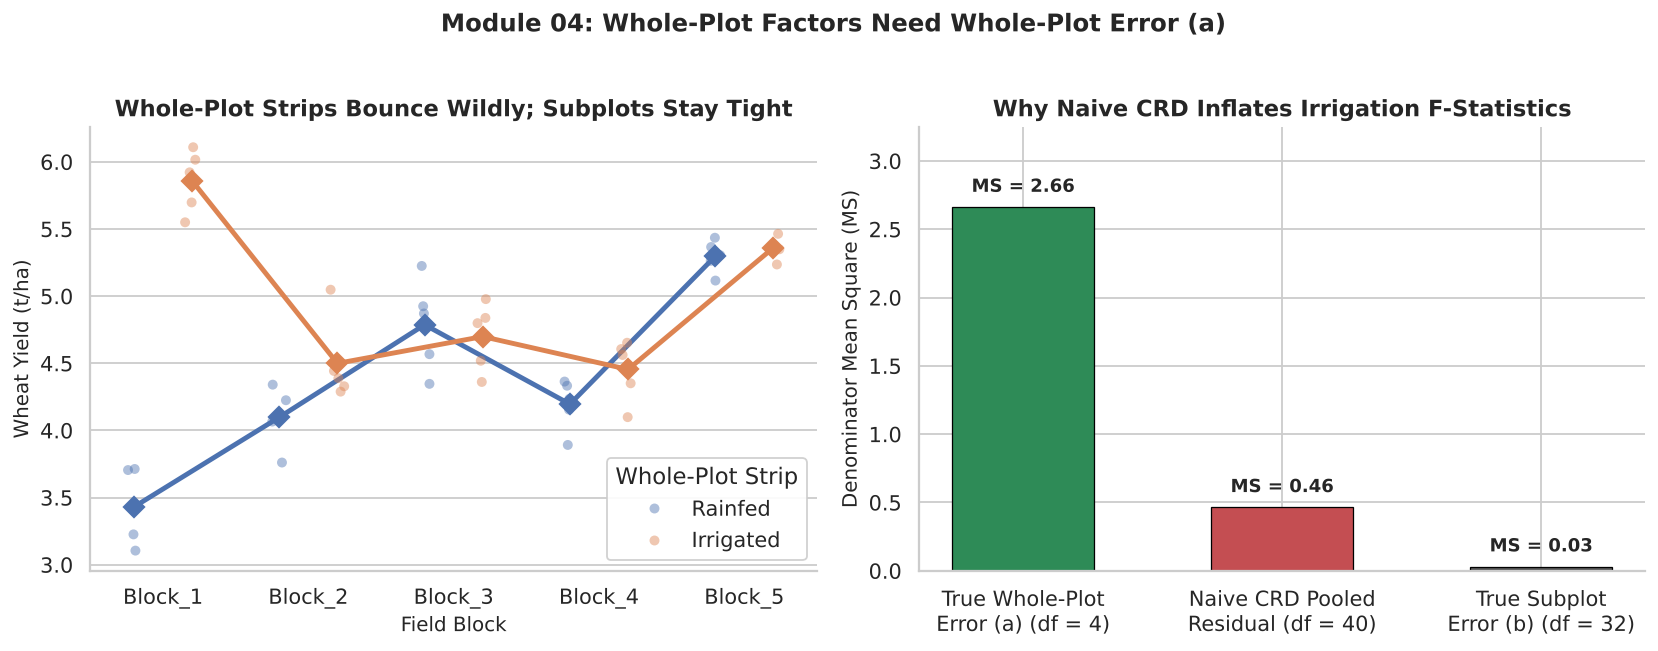

In [3]:
# Compute whole-plot and subplot ANOVA mean squares
wp_means = df.groupby(["block", "irrigation"], as_index=False, observed=True)["yield_t_ha"].mean()
wp_ols = smf.ols("yield_t_ha ~ C(block) + C(irrigation)", data=wp_means).fit()
aov_wp = anova_lm(wp_ols)

# Full split-plot fixed-effects decomposition for exact Error(a) and Error(b) MS (per-subplot scale)
sp_full = smf.ols("yield_t_ha ~ C(block) * C(irrigation) + C(cultivar) + C(irrigation):C(cultivar)", data=df).fit()
aov_sp = anova_lm(sp_full)
ms_err_a = float(aov_sp.loc["C(block):C(irrigation)", "mean_sq"])
ms_err_b = float(aov_sp.loc["Residual", "mean_sq"])
ms_crd = float(naive_crd.mse_resid)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.9))
irr_palette = {"Rainfed": PALETTE["control"], "Irrigated": PALETTE["treated"]}

# Panel A: Whole-Plot Strip Means vs Subplot Spread
sns.stripplot(
    data=df, x="block", y="yield_t_ha", hue="irrigation",
    palette=irr_palette, dodge=True, alpha=0.45, size=5.5, ax=axes[0]
)
sns.pointplot(
    data=wp_means, x="block", y="yield_t_ha", hue="irrigation",
    palette=irr_palette, dodge=0.4, linestyles="-", markers="D", capsize=0.0, ax=axes[0], legend=False
)
axes[0].set_title("Whole-Plot Strips Bounce Wildly; Subplots Stay Tight")
axes[0].set_xlabel("Field Block")
axes[0].set_ylabel("Wheat Yield (t/ha)")
axes[0].legend(title="Whole-Plot Strip", loc="lower right")

# Panel B: Error Mean Squares Used in F-test Denominator
ms_labels = [
    "True Whole-Plot\nError (a) (df = 4)",
    "Naive CRD Pooled\nResidual (df = 40)",
    "True Subplot\nError (b) (df = 32)",
]
ms_vals = [ms_err_a, ms_crd, ms_err_b]
ms_colors = [PALETTE["safe"], PALETTE["danger"], PALETTE["neutral"]]
bars = axes[1].bar(ms_labels, ms_vals, color=ms_colors, width=0.55, edgecolor="black", linewidth=0.7)
for bar, val in zip(bars, ms_vals):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val + 0.08,
        f"MS = {val:.2f}", ha="center", va="bottom", fontweight="bold", fontsize=10
    )
axes[1].set_ylim(0, max(ms_vals) * 1.22)
axes[1].set_title("Why Naive CRD Inflates Irrigation F-Statistics")
axes[1].set_ylabel("Denominator Mean Square (MS)")

fig.suptitle("Module 04: Whole-Plot Factors Need Whole-Plot Error (a)", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. The Fix (Proper Model)

We fit both the **Split-Plot Mixed-Effects Model (`MixedLM`)** with a random intercept per `whole_plot_id` (`Block × Irrigation` strip) and the classic **Exact Split-Plot Whole-Plot ANOVA (`Error (a)`, `df = 4`)**. Notice the split-plot magic: Irrigation vanishes (`p = 0.18` / `0.26`), while the subplot factor `Cultivar` (`Var_1`–`Var_5`, tested cleanly against `Error (b)`) remains genuinely significant (`p < 0.001`)! The explicit split-plot ANOVA table after the summary shows every test against its proper error stratum.

In [4]:
mlm = smf.mixedlm(
    "yield_t_ha ~ C(block) + C(irrigation) * C(cultivar, Sum)",
    data=df, groups=df["whole_plot_id"]
).fit(reml=True)

est_mlm = float(mlm.fe_params["C(irrigation)[T.Irrigated]"])
ci_mlm = mlm.conf_int().loc["C(irrigation)[T.Irrigated]"].tolist()
p_mlm = float(mlm.pvalues["C(irrigation)[T.Irrigated]"])

est_wp = float(wp_ols.params["C(irrigation)[T.Irrigated]"])
ci_wp = wp_ols.conf_int().loc["C(irrigation)[T.Irrigated]"].tolist()
p_wp = float(aov_wp.loc["C(irrigation)", "PR(>F)"])

# Verify that subplot Cultivar effect stays genuinely detectable!
cv_terms = [f"C(cultivar, Sum)[S.Var_{i}] = 0" for i in range(1, 5)]
p_cultivar_mlm = float(mlm.wald_test(", ".join(cv_terms), scalar=True).pvalue)
print(f"Subplot Cultivar main effect (MixedLM Wald test): p = {format_p_value(p_cultivar_mlm)} (still detected!)\n")

summary = build_comparison_table(
    [
        {
            "Model": "Naive CRD Two-Way ANOVA",
            "Assumed Unit": "50 independent subplots",
            "df_resid": int(naive_crd.df_resid),
            "Estimate": f"{est_bad:+.2f} t/ha (Irr-Rain)",
            "95% CI": f"[{ci_bad[0]:+.2f}, {ci_bad[1]:+.2f}]",
            "p_value": format_p_value(p_irr_bad),
            "Verdict": "Fake significance (p < 0.01)",
        },
        {
            "Model": "Proper Split-Plot MixedLM",
            "Assumed Unit": "10 whole-plot strips (REML)",
            "df_resid": "10 strips",
            "Estimate": f"{est_mlm:+.2f} t/ha (Irr-Rain)",
            "95% CI": f"[{ci_mlm[0]:+.2f}, {ci_mlm[1]:+.2f}]",
            "p_value": format_p_value(p_mlm),
            "Verdict": "Truth recovered (no irr. effect)",
        },
        {
            "Model": "Exact Whole-Plot Error(a) ANOVA",
            "Assumed Unit": "10 strip means across 5 blocks",
            "df_resid": int(wp_ols.df_resid),
            "Estimate": f"{est_wp:+.2f} t/ha (Irr-Rain)",
            "95% CI": f"[{ci_wp[0]:+.2f}, {ci_wp[1]:+.2f}]",
            "p_value": format_p_value(p_wp),
            "Verdict": "Truth recovered (exact df=4)",
        },
    ]
)
summary

Subplot Cultivar main effect (MixedLM Wald test): p = 2.57e-05 (still detected!)



,Model,Assumed Unit,df_resid,Estimate,95% CI,p_value,Verdict
0,Naive CRD Two-Way ANOVA,50 independent subplots,40,+0.61 t/ha (Irr-Rain),"[+0.22, +1.00]",0.0029,Fake significance (p < 0.01)
1,Proper Split-Plot MixedLM,10 whole-plot strips (REML),10 strips,+0.61 t/ha (Irr-Rain),"[-0.29, +1.52]",0.1843,Truth recovered (no irr. effect)
2,Exact Whole-Plot Error(a) ANOVA,10 strip means across 5 blocks,4,+0.61 t/ha (Irr-Rain),"[-0.67, +1.89]",0.2550,Truth recovered (exact df=4)


### The explicit split-plot ANOVA

The `MixedLM` Wald test above is one way to test cultivar. The classic, fully explicit route is the split-plot ANOVA, where **each factor is tested against the error term of the level it was randomized at**:

| Source | df | Tested against |
|---|---|---|
| Irrigation (whole plot) | 1 | Error(a) = Block × Irrigation, df = 4 |
| Cultivar (subplot) | 4 | Error(b), df = 32 |
| Irrigation × Cultivar | 4 | Error(b), df = 32 |

`split_plot_anova()` in `src/simulate_blunders.py` builds exactly this table.

In [5]:
sp_table = split_plot_anova(df)

for term in ["Irrigation", "Cultivar", "Irrigation x Cultivar"]:
    row = sp_table.loc[term]
    err_df = int(row["Error term"].split("df = ")[1])
    print(f"{term:<22} F({row['df']}, {err_df}) = {row['F']:6.2f}, p = {format_p_value(row['p_value'])}  [vs {row['Error term']}]")

sp_table.round(4)

Irrigation             F(1, 4) =   1.76, p = 0.2550  [vs Error(a), df = 4]
Cultivar               F(4, 32) =   8.75, p = 6.88e-05  [vs Error(b), df = 32]
Irrigation x Cultivar  F(4, 32) =   1.86, p = 0.1422  [vs Error(b), df = 32]


,df,SS,MS,F,p_value,Error term
Source,,,,,,
Block,4,6.9659,1.7415,NaN,NaN,
Irrigation,1,4.6922,4.6922,1.7624,0.2550,"Error(a), df = 4"
Error(a): Block x Irrigation,4,10.6498,2.6625,NaN,NaN,
Cultivar,4,1.0565,0.2641,8.7473,0.0001,"Error(b), df = 32"
Irrigation x Cultivar,4,0.2244,0.0561,1.8577,0.1422,"Error(b), df = 32"
Error(b): subplot residual,32,0.9662,0.0302,NaN,NaN,


> **Rule of Thumb:** Every randomization tier gets its own error term: test whole-plot factors against whole-plot error (`Block × Whole-Plot` or a random `whole_plot_id` intercept), and reserve subplot residual error strictly for subplot factors and interactions. Whenever a treatment is harder to apply at small scales (irrigation, tillage, temperature chambers), expect fewer effective degrees of freedom for it.